# Books Recommendation Engine

* This notebook recommends a set of books similar to other books based on crowdsourced book rating by users
* It uses item based collberative filtering to achieve this
* Citation: Books dataset was gotten from the university inventory


In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
from numpy import int64

import requests
import IPython.display as Disp

import sklearn
from sklearn.decomposition import TruncatedSVD


### Books and Ratings info

In [11]:
 books_df = pd.read_csv("./dataset/books.csv")
ratings_df = pd.read_csv("./dataset/Newratings.csv", encoding='UTF-8',  dtype={'user_id': int,'book_id':int, 'rating':int} )

In [13]:
books_df.head()
#ratings_df.head()

,book_id,Location,authors,original_title,title,language_code,average_rating,image_url,small_image_url
0,1,QA7 .F68 1994,NaN,For all practical purposes,For all practical purposes,eng,4.34,https://images.gr-assets.com/books/1444323423m...,https://images.gr-assets.com/books/1444323423s...
1,2,QA7 .F68 2003,NaN,For all practical purposes,For all practical purposes,eng,4.44,https://images.gr-assets.com/books/1444154222m...,https://images.gr-assets.com/books/1444154222s...
2,3,QA71 .B58 1997,"Bittinger, Marvin L.",Graphing calculator manual,Graphing calculator manual,en-US,3.57,https://images.gr-assets.com/books/134534443m/...,https://images.gr-assets.com/books/134534443s/...
3,4,QA71 .S94 2004,"McLaughlin, Kathleen and Dorothy Wakefield","TI-83, TI-83 Plus and TI-83 Silver Edition Gra...","TI-83, TI-83 Plus and TI-83 Silver Edition Gra...",eng,4.25,https://images.gr-assets.com/books/1341445452m...,https://images.gr-assets.com/books/1341445452s...
4,5,QA73.4 .I48 2003,NaN,COMPUTER PREP,COMPUTER PREP,eng,3.89,https://images.gr-assets.com/books/1442525542m...,https://images.gr-assets.com/books/1442525542s...


In [15]:
books_df.describe()
books_df_2 = books_df[['book_id', 'average_rating','original_title','image_url','authors']]

books_df_2.head()

len(books_df)

2000

In [57]:
ratings_df.describe()

,user_id,book_id,rating
count,19627.000000,19627.000000,19627.000000
mean,103.550772,488.892444,4.259693
std,58.109510,517.474867,0.457026
min,1.000000,1.000000,1.000000
25%,56.000000,80.000000,4.000000
50%,91.000000,248.000000,4.000000
75%,166.000000,755.000000,5.000000
max,200.000000,2000.000000,5.000000


In [21]:
ratings_df.groupby('user_id')['rating'].count()

user_id
1       18
2       13
3       15
4       12
5       15
      ... 
196    252
197    533
198    127
199    140
200     88
Name: rating, Length: 200, dtype: int64

## Merge books and ratings dataset

In [23]:
combined_books_df = pd.merge(ratings_df, books_df, on='book_id')

In [25]:
combined_books_df.head()

,user_id,book_id,rating,Location,authors,original_title,title,language_code,average_rating,image_url,small_image_url
0,1,7,5,QA74.76.M52 P279 2003,NaN,New perspectives on Microsoft Office XP,New perspectives on Microsoft Office XP,en-US,4.25,https://images.gr-assets.com/books/1342544522m...,https://images.gr-assets.com/books/1342544522s...
1,1,30,1,QA76 .L56 1991,NaN,Introducing Microsoft Windows 95,Introducing Microsoft Windows 95,eng,4.03,https://images.gr-assets.com/books/1334422131m...,https://images.gr-assets.com/books/1334422131s...
2,1,140,5,QA76.3 .S44,"Sellers, Joseph P",Microsoft Windows 2000 Active Directory Lab Ma...,Microsoft Windows 2000 Active Directory Lab Ma...,en-US,4.20,https://images.gr-assets.com/books/1324425242m...,https://images.gr-assets.com/books/1324425242s...
3,1,141,5,QA76.3 .S445,"Sellers, Joseph P",Microsoft Windows 2000 Active Directory Lab Ma...,Microsoft Windows 2000 Active Directory Lab Ma...,eng,4.39,https://images.gr-assets.com/books/1413424254m...,https://images.gr-assets.com/books/1413424254s...
4,1,175,2,QA76.5 .L3325 1993,"Larsen, Gwynne.",Using Microsoft Works,Using Microsoft Works,eng,4.50,https://images.gr-assets.com/books/1324424544m...,https://images.gr-assets.com/books/1324424544s...


### Data cleaning and preprocessing

In [27]:
# Drop unnecessary columns
combined_books_df = combined_books_df[['user_id', 'book_id', 'original_title', 'rating']]

combined_books_df.drop_duplicates(subset=['user_id', 'book_id'], inplace=True)

combined_books_df.dropna(inplace=True)


In [100]:
# min_ratings = 10
#user_counts = combined_books_df['user_id'].value_counts()
#filtered_users = user_counts[user_counts >= min_ratings].index
#combined_books_df = combined_books_df[combined_books_df['user_id'].isin(filtered_users)]

#combined_books_df.reset_index(drop=True, inplace=True)


#print(combined_books_df.head())

### Get most rated books

In [29]:
combined_books_df.groupby('book_id')['rating'].count().sort_values(ascending=False)

book_id
21      71
26      68
4       68
27      66
18      64
        ..
1499     1
929      1
927      1
1502     1
1        1
Name: rating, Length: 1498, dtype: int64

In [31]:
Filter = combined_books_df['book_id'] < 10
combined_books_df[Filter]['original_title'].unique()
#printBookCover(Filter)

array(['New perspectives on Microsoft Office XP ',
       'Graphing calculator manual ',
       'TI-83, TI-83 Plus and TI-83 Silver Edition Graphing Calculator Manual',
       'Electronic Calculators  A Mastery Approach', 'COMPUTER PREP',
       'For all practical purposes ',
       'An Easy Course In Using The HP-28c', 'CA-Clipper'], dtype=object)

### Create Pivot Table of User Vs Movies

In [35]:
ct_df = combined_books_df.pivot_table(values='rating', index='user_id', columns='original_title', fill_value=0)

In [37]:
ct_df.head()

original_title,Decorate Your House with Elegant Handmade Projects | Learn Basic Knot Patterns with Step-by-Step Images as You Relax in the Comfort of Your Home,Go Technology in action,Software Engineering.,Transition from observation to knowledge to intelligence,Wordperfect six.O Dosi professional skills,100 Days of Code Learning Journal: Notebook for Python programming beginners/learners. Gift for programmer. Progress tracker. Game /Coding Projects.,101 Microsoft Visual Basic.NET applications,24 Seven Windows client administration,"2Pack Reptile Plants Hanging Silk Terrarium Plants with Suction Cup for Bearded Dragons,Lizards,Geckos,Snake,Hermit Crab Tank Habitat Decorations,Small Size,12 inches Green",3D Deep Learning with Python: Design and develop your computer vision model with 3D data using PyTorch3D and more,...,Writing CGI application with Perl,Writing for multimedia,X Window System Programming,XHTML comprehensive,XML FOR DUMMIES,XML bible,"Zoo Med Reptile Rock Corner Water Dish, Large - Assorted colors",a b c in mathematical methods (a),i-Net Guide to the Internet,iLife '06
user_id,,,,,,,,,,,,,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [39]:
X = ct_df.values.T
X.shape

(1388, 200)

### Compress dataset by applying Singular Value Decomposistion (SVD)

In [41]:
SVD  = TruncatedSVD(n_components=20, random_state=17)
result_matrix = SVD.fit_transform(X)
result_matrix.shape

(1388, 20)

### Create Pearson coorelation matrix

In [43]:
corr_mat = np.corrcoef(result_matrix)
corr_mat.shape

(1388, 1388)

### Print books related to specified book


In [45]:
book_names = ct_df.columns
book_list = list(book_names)
os_book = book_list.index('Operating systems and architecture')


In [47]:
corr_book = corr_mat[os_book]
corr_book.shape

(1388,)

In [49]:
list(book_names[(corr_book<1.0) & (corr_book>0.8)])

['AFRICAN JOURNAL OF COMPUTING AND ICTs',
 "Basic Computer Studies a beginners's text",
 'C   how to program ',
 'COMPUTER PREP',
 'Computer concepts ',
 'Computers information technology in perspective',
 'Computing concepts ',
 'Computing, information systems & development informatics journal.',
 'Core MCSE ',
 'Electronic Calculators  A Mastery Approach',
 'Excel Data Analysis: Your visual blueprint for analyzing data, charts, and PivotTables',
 'How to write usable user documentation ',
 'Instruction solution manual to accompany basic mathematical skills with geometry ',
 'Introduction to Computer Concepts ',
 'Introduction to computer and its application',
 'MCSE designing security for Windows 2000 ',
 'Managing and Maintaining a windows Server 2003 Environment',
 'Microcomputer',
 'New perspectives on Microsoft Office XP ',
 'New perspectives on computer concepts ',
 'Novell certification handbook ',
 'Pratical PC',
 "Prentice Hall's MOUS test preparation guide for Word 2000 ",
 

In [114]:
# MAE

Recall scores: [0.002366975130133025, 0.0008294510786770847, 0.002742349533253423, 0.004323106373593846, 0.0022077964873840807, 0.0032869118385174165, 0.004247523937016174, 0.002584204752935403, 0.0040019114271957435, 0.0030388241165937996]
Average Recall: 0.00296290546753
Recall standard deviation: 0.001017825013966589


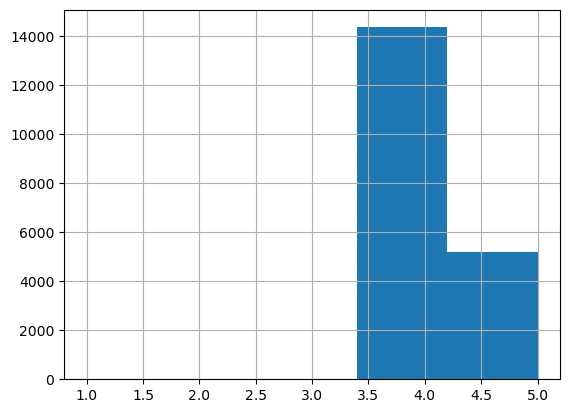

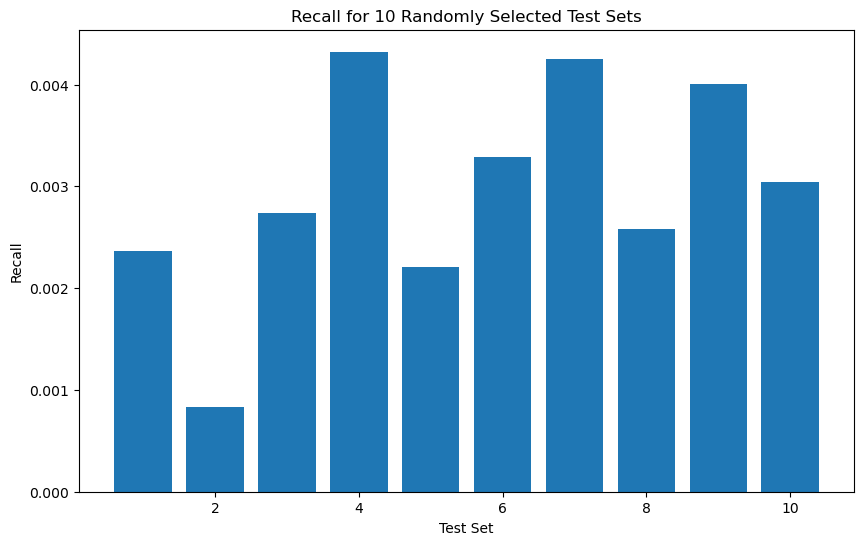

MAE Evaluation Results


,Training Ratio,Testing Ratio,Average MAE,MAE Std Dev,Evaluated Ratings
0,50%,50%,0.397355,0.001417,6579.8
1,60%,40%,0.393743,0.000875,5332.6
2,70%,30%,0.393928,0.001645,4025.2
3,80%,20%,0.394527,0.002546,2690.4
4,90%,10%,0.397884,0.003250,1352.4


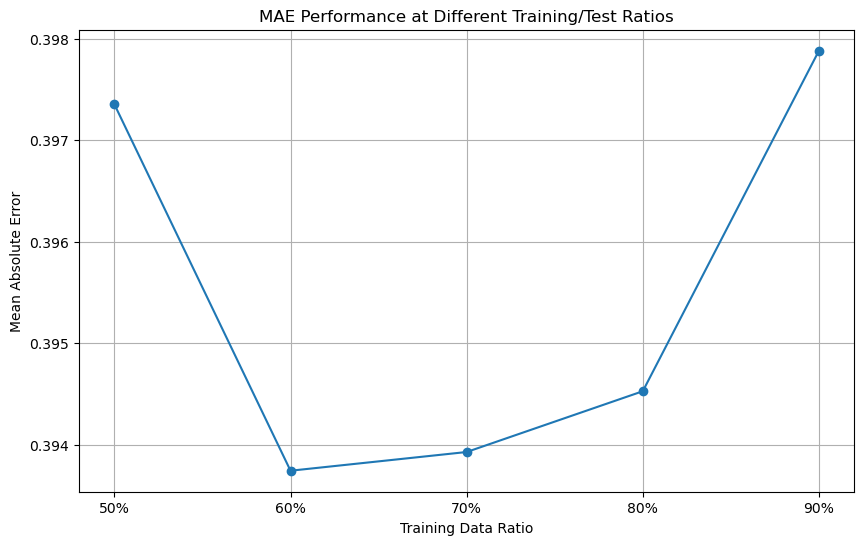

In [51]:

from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Prepare evaluation data
evaluation_df = combined_books_df[
    ['user_id', 'book_id', 'rating']
].dropna().copy()

evaluation_df['user_id'] = evaluation_df['user_id'].astype(int)
evaluation_df['book_id'] = evaluation_df['book_id'].astype(int)

evaluation_df = evaluation_df.drop_duplicates(
    subset=['user_id', 'book_id']
).reset_index(drop=True)


# Split ratings separately for each user.
# This ensures that users with at least two ratings
# have ratings in both training and testing data.

def split_by_user(data, test_size=0.2, random_state=42):

    rng = np.random.default_rng(random_state)

    train_indices = []
    test_indices = []

    for user_id, group in data.groupby('user_id'):

        indices = group.index.to_numpy()

        if len(indices) < 2:
            train_indices.extend(indices)
            continue

        n_test = min(
            len(indices) - 1,
            max(1, int(round(len(indices) * test_size)))
        )

        selected = rng.choice(
            indices,
            size=n_test,
            replace=False
        )

        test_indices.extend(selected)

        train_indices.extend(
            np.setdiff1d(indices, selected)
        )

    train_data = data.loc[train_indices].copy()
    test_data = data.loc[test_indices].copy()

    return train_data, test_data


# Build the SVD and Pearson similarity model

def build_item_model(train_data):

    pivot = train_data.pivot_table(
        values='rating',
        index='user_id',
        columns='book_id',
        fill_value=0
    )

    X_train = pivot.values.T

    if min(X_train.shape) < 2:
        raise ValueError(
            "Not enough users or books to perform SVD."
        )

    n_components = min(
        20,
        min(X_train.shape) - 1
    )

    svd = TruncatedSVD(
        n_components=n_components,
        random_state=17
    )

    result_matrix = svd.fit_transform(X_train)

    corr_matrix = np.corrcoef(result_matrix)

    corr_matrix = np.nan_to_num(
        corr_matrix,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    np.fill_diagonal(corr_matrix, 1.0)

    return pivot, corr_matrix


# Predict a user's rating for a book

def predict_rating(
    user_id,
    book_id,
    pivot,
    corr_matrix,
    global_mean,
    k=20
):

    if user_id not in pivot.index:
        return global_mean

    user_ratings = pivot.loc[user_id].values

    rated_indices = np.where(user_ratings > 0)[0]

    if len(rated_indices) == 0:
        return global_mean

    user_mean = np.mean(user_ratings[rated_indices])

    if book_id not in pivot.columns:
        return user_mean

    book_index = pivot.columns.get_loc(book_id)

    similarities = corr_matrix[
        book_index, rated_indices
    ].copy()

    ratings = user_ratings[rated_indices]

    # Exclude the target book from its own prediction
    valid = rated_indices != book_index

    similarities = similarities[valid]
    ratings = ratings[valid]

    if len(similarities) == 0:
        return user_mean

    # Use the strongest neighbours
    top_indices = np.argsort(
        np.abs(similarities)
    )[-k:]

    similarities = similarities[top_indices]
    ratings = ratings[top_indices]

    denominator = np.sum(np.abs(similarities))

    if denominator == 0:
        return user_mean

    centered_ratings = ratings - user_mean

    prediction = (
        user_mean +
        np.dot(similarities, centered_ratings) / denominator
    )

    return np.clip(prediction, 1, 5)


# Generate top-N recommendations for a user

def predict_top_n(
    user_id,
    pivot,
    corr_matrix,
    global_mean,
    n=5
):

    if user_id not in pivot.index:
        return []

    user_ratings = pivot.loc[user_id].values

    # Only recommend books the user has not rated
    unrated_indices = np.where(user_ratings == 0)[0]

    if len(unrated_indices) == 0:
        return []

    predictions = []

    for index in unrated_indices:

        book_id = pivot.columns[index]

        score = predict_rating(
            user_id,
            book_id,
            pivot,
            corr_matrix,
            global_mean
        )

        predictions.append((book_id, score))

    predictions.sort(
        key=lambda x: x[1],
        reverse=True
    )

    return [
        book_id for book_id, score in predictions[:n]
    ]


# Calculate Recall

def calculate_recall(
    test_data,
    recommended_books
):

    relevant_books = set(
        test_data.loc[
            test_data['rating'] >= 4,
            'book_id'
        ]
    )

    recommended_books = set(recommended_books)

    if len(relevant_books) == 0:
        return None

    hits = relevant_books.intersection(
        recommended_books
    )

    return len(hits) / len(relevant_books)


# Evaluate Recall over 10 different splits

def recall_test(
    n_splits=10,
    n_top=5
):

    recalls = []

    for split in range(n_splits):

        train_data, test_data = split_by_user(
            evaluation_df,
            test_size=0.2,
            random_state=17 + split
        )

        pivot, corr_matrix = build_item_model(train_data)

        global_mean = train_data['rating'].mean()

        user_recalls = []

        for user_id in test_data['user_id'].unique():

            user_test = test_data[
                test_data['user_id'] == user_id
            ]

            # Only evaluate relevant books in the training catalogue
            relevant_test = user_test[
                (user_test['rating'] >= 4) &
                (user_test['book_id'].isin(pivot.columns))
            ]

            if relevant_test.empty:
                continue

            recommendations = predict_top_n(
                user_id,
                pivot,
                corr_matrix,
                global_mean,
                n=n_top
            )

            recall = calculate_recall(
                relevant_test,
                recommendations
            )

            if recall is not None:
                user_recalls.append(recall)

        if user_recalls:
            recalls.append(np.mean(user_recalls))

    return recalls


# Run Recall evaluation

recalls = recall_test(n_splits=10, n_top=5)

print("Recall scores:", recalls)

if recalls:
    print("Average Recall:", np.mean(recalls))
    print("Recall standard deviation:", np.std(recalls))

    plt.figure(figsize=(10, 6))
    plt.bar(range(1, len(recalls) + 1), recalls)

    plt.xlabel("Test Set")
    plt.ylabel("Recall")
    plt.title("Recall for 10 Randomly Selected Test Sets")
    plt.show()


# Calculate MAE

def calculate_mae(
    split_ratio,
    random_state=42
):

    train_data, test_data = split_by_user(
        evaluation_df,
        test_size=split_ratio,
        random_state=random_state
    )

    pivot, corr_matrix = build_item_model(train_data)

    global_mean = train_data['rating'].mean()

    # Only evaluate books available in the training catalogue
    test_data = test_data[
        test_data['book_id'].isin(pivot.columns)
    ]

    true_ratings = []
    predicted_ratings = []

    for _, row in test_data.iterrows():

        prediction = predict_rating(
            row['user_id'],
            row['book_id'],
            pivot,
            corr_matrix,
            global_mean
        )

        true_ratings.append(row['rating'])
        predicted_ratings.append(prediction)

    if not true_ratings:
        return None, 0

    mae = mean_absolute_error(
        true_ratings,
        predicted_ratings
    )

    return mae, len(true_ratings)


# Test different training and testing ratios

split_ratios = [0.5, 0.4, 0.3, 0.2, 0.1]

results = []

for split_ratio in split_ratios:

    mae_list = []
    evaluated_counts = []

    for iteration in range(5):

        mae, count = calculate_mae(
            split_ratio,
            random_state=42 + iteration
        )

        if mae is not None:
            mae_list.append(mae)
            evaluated_counts.append(count)

    if mae_list:

        results.append({
            'Training Ratio': f'{(1-split_ratio)*100:.0f}%',
            'Testing Ratio': f'{split_ratio*100:.0f}%',
            'Average MAE': np.mean(mae_list),
            'MAE Std Dev': np.std(mae_list),
            'Evaluated Ratings': np.mean(evaluated_counts)
        })


results_df = pd.DataFrame(results)

print("MAE Evaluation Results")

display(results_df)


# Plot MAE results

if not results_df.empty:

    plt.figure(figsize=(10, 6))

    plt.plot(
        results_df['Training Ratio'],
        results_df['Average MAE'],
        marker='o'
    )

    plt.xlabel("Training Data Ratio")
    plt.ylabel("Mean Absolute Error")
    plt.title("MAE Performance at Different Training/Test Ratios")

    plt.grid(True)
    plt.show()
